# Processing and analysis of SEQC cohort bulk RNA-seq data

In [49]:
# Set working directory and load relevant packages
library(plyr)
library(dplyr)
library(ggrepel)
library(ggplot2)
library(DescTools)
library(dplyr)
library(tidyr)
library(DESeq2)

source("../sc_analysis_palettes_and_helpers.r")

setwd('data/bulkRNAseq/SEQC/')

## Load data
log2 normalised and metadata

In [7]:

norm_dat <- read.delim('/local/users/nfresma/TCGA_bulk_RNAseq/GSE49711/GSE49711_SEQC_NB_TUC_G_log2.txt',
                     stringsAsFactors = F, header = T, sep = '\t', row.names = 1)

meta_dat <- read.delim('/local/users/nfresma/TCGA_bulk_RNAseq/GSE49711/metadata_Rready.csv',
                     stringsAsFactors = F, header = T, sep = ';', row.names = 1)


meta_dat_surv <- read.delim('/local/users/nfresma/TCGA_bulk_RNAseq/GSE49711/GSE62564_metadata_for_GSE49711.csv',
                     stringsAsFactors = F, header = T, sep = ';', row.names = 1)

meta_dat_surv$os_day <- as.numeric(gsub('os day: ','',meta_dat_surv$characteristics_ch1.5))
meta_dat_surv$efs_day <- as.numeric(gsub('efs day: ','',meta_dat_surv$characteristics_ch1.3))
meta_dat_surv$os_bin <- meta_dat_surv$os.bin.ch1
meta_dat_surv$efs_bin <- meta_dat_surv$efs.bin.ch1
meta_dat_surv$title <- gsub(' \\[2\\]','',meta_dat_surv$title)
meta_dat_surv$title <- gsub('SEQC_','',meta_dat_surv$title)

meta_dat_surv <- meta_dat_surv[,c('title','os_day','efs_day','os_bin','efs_bin')]
head(meta_dat_surv)
meta_dat$title <- rownames(meta_dat)

meta_dat_all <- left_join(meta_dat, meta_dat_surv, by = 'title')
rownames(meta_dat_all) <- meta_dat_all$title

,title,os_day,efs_day,os_bin,efs_bin
,<chr>,<dbl>,<dbl>,<int>,<int>
GSM1528894,NB001,1362,593,1,1
GSM1528895,NB002,2836,2016,1,1
GSM1528896,NB003,1191,840,1,1
GSM1528897,NB004,2046,2046,0,0
GSM1528898,NB005,220,212,1,1
GSM1528899,NB006,2217,2217,0,0


## Filter data
based on https://www.bioconductor.org/packages/release/workflows/vignettes/rnaseqGene

In [8]:
# Keep only genes that have a count above 0 in more than three samples

# Define the condition: value > 0
condition <- norm_dat > 0

# Apply the condition to each row and count how many columns meet it
row_counts <- apply(condition, 1, sum)

# Filter rows where at least 4 columns meet the condition
filtered_matrix <- norm_dat[row_counts > 3, ]


## Score modules

In [9]:
# Function for scoring
# Adapted https://github.com/HerpelinckT/geneset-modulescoring
# Here this was adapted to simply take the filtered and FPKM-normalized matrix instead of a DEseq2 object

AddGeneSetScore <- function(
  dds,
  features,
  pool = NULL,
  nbin = 24,
  ctrl = 100,
  name = 'Set',
  seed = 123
) {
  if (!is.null(x = seed)) {
    set.seed(seed = seed)
  }
  
  `%||%` <- function(a, b) if (!is.null(a)) a else b
  
  object <- dds # used to be counts(dds) to use non-normalized counts or assay(dds) to use normalized counts from a DEseq2 object.
  object.old <- object
  object <- object %||% object.old
  
  features <- list(features)
  features.old <- features
  
  if (is.null(x = features)) {
    stop("Missing input feature list")
  }
  features <- lapply(
    X = features,
    FUN = function(x) {
      missing.features <- setdiff(x = x, y = rownames(x = object))
      if (length(x = missing.features) > 0) {
        warning(
          "The following features are not present in the object: ",
          paste(missing.features, collapse = ", ")
        ) 
        warning(
          paste0("\n ",
                 paste(missing.features, collapse = ", "),
                 " dropped for calculating the geneset score."
          )
        )
      }
      return(intersect(x = x, y = rownames(x = object)))
    }
  )
  
  geneset.length <- length(x = features)
  
  pool <- pool %||% rownames(x = object)
  data.avg <- Matrix::rowMeans(x = object[pool, ])
  data.avg <- data.avg[order(data.avg)]
  data.cut <- cut_number(x = data.avg + rnorm(n = length(data.avg))/1e30, n = nbin, labels = FALSE, right = FALSE)
  names(x = data.cut) <- names(x = data.avg)
  ctrl.use <- vector(mode = "list", length = geneset.length)
  for (i in 1:geneset.length) {
    features.use <- features[[i]]
    for (j in 1:length(x = features.use)) {
      ctrl.use[[i]] <- c(
        ctrl.use[[i]],
        names(x = sample(
          x = data.cut[which(x = data.cut == data.cut[features.use[j]])],
          size = ctrl,
          replace = FALSE
        ))
      )
    }
  }
  ctrl.use <- lapply(X = ctrl.use, FUN = unique)
  ctrl.scores <- matrix(
    data = numeric(length = 1L),
    nrow = length(x = ctrl.use),
    ncol = ncol(x = object)
  )
  for (i in 1:length(ctrl.use)) {
    features.use <- ctrl.use[[i]]
    ctrl.scores[i, ] <- Matrix::colMeans(x = object[features.use, ])
  }
  features.scores <- matrix(
    data = numeric(length = 1L),
    nrow = geneset.length,
    ncol = ncol(x = object)
  )
  for (i in 1:geneset.length) {
    features.use <- features[[i]]
    data.use <- object[features.use, , drop = FALSE]
    features.scores[i, ] <- Matrix::colMeans(x = data.use)
  }
  features.scores.use <- features.scores - ctrl.scores
  rownames(x = features.scores.use) <- paste0(name, 1:geneset.length)
  features.scores.use <- as.data.frame(x = t(x = features.scores.use))
  
  range01 <- lapply(
    X = features.scores.use,
    FUN = function(x) {
      range01 <- (x-min(x))/(max(x)-min(x))
    }
  )
  
  range01 <- as.data.frame(x = range01)
  rownames(x = range01) <- colnames(object)
  
  
  return(range01)
}

### Load zebrafish NB modules and score those

In [14]:
modules_pan <- read.csv(file = '../../../final_mod_mat_DRNB_HSversion_finalNames.csv', stringsAsFactors = F, sep = ',', row.names = 1, header = T)

modules_pan <- as.list(modules_pan)
modules_pan <- lapply(modules_pan, function(x) x[!is.na(x)])
modules_pan <- lapply(modules_pan, function(x) x[x != 'NA'])
modules_pan <- lapply(modules_pan, function(x) x[x %in% rownames(filtered_matrix)])

modules_all <- modules_pan[lengths(modules_pan) > 5]
                      
# adjust to short names
names(modules_all)[names(modules_all) == 'nervous_system_dev_neuronprojection'] <- 'neuron_projection'
names(modules_all)[names(modules_all) == 'nervous_system_dev_01'] <- 'nervous_system_dev'
                      

In [15]:
# set metadata columns for plotting
meta_dat$sample_id <- rownames(meta_dat)

meta_dat$INSS_sum <- meta_dat$INSS
meta_dat$INSS_sum[meta_dat$INSS_sum %like any% c('2','2a','2b')] <- '2'

meta_dat$MYCN_stat_plot <- meta_dat$MYCN_status
meta_dat$MYCN_stat_plot[meta_dat$MYCN_stat_plot == '1'] <- 'nonAmp'
meta_dat$MYCN_stat_plot[meta_dat$MYCN_stat_plot == 'n.e.'] <- NA
meta_dat$MYCN_stat_plot <- factor(as.character(meta_dat$MYCN_stat_plot), levels = c('nonAmp','Amp',NA))

meta_dat$MYCN_INSS <- paste0(meta_dat$MYCN_stat_plot, '_', meta_dat$INSS_sum)
meta_dat$MYCN_INSS[meta_dat$MYCN_INSS %like any% 'NA%'] <- NA

meta_dat$HighRisk <- as.character(meta_dat$HighRisk)
meta_dat$HighRisk[meta_dat$HighRisk == ''] <- 'non-HR'
meta_dat$HighRisk <- factor(as.character(meta_dat$HighRisk), levels = c('HR','non-HR'))


meta_dat$HR_MYCN <- paste0(meta_dat$HighRisk, '_', meta_dat$MYCN_stat_plot)
meta_dat$HR_MYCN[meta_dat$HR_MYCN %like any% '%NA'] <- NA
meta_dat$HR_MYCN <- factor(as.character(meta_dat$HR_MYCN), levels = c('non-HR_nonAmp','HR_nonAmp','HR_Amp',NA))

In [17]:
# Define function for getting stats in a format allowing to add them to a plot downstream

pairwise_wilcox_for_plot <- function(set_name, group_name, dataframe){

    # Perform pairwise Wilcoxon tests
        pairwise_results <- pairwise.wilcox.test(
          dataframe[, set_name],  # Scores
          dataframe[, group_name],        # Grouping variable
          p.adjust.method = "bonferroni"  # Adjust method
        )

        # Convert pairwise results to a long format dataframe
        significant_pairs <- as.data.frame(pairwise_results$p.value) %>%
          tibble::rownames_to_column("group1") %>%
          pivot_longer(cols = -group1, names_to = "group2", values_to = "p_value") %>%
          filter(!is.na(p_value))  # Filter significant results
        #  filter(!is.na(p_value) & p_value < 0.05)  # Filter significant results

        # Define y positions for annotation lines
        y_positions <- seq(max(dataframe[, set_name]) + 0.1, 
                           by = 0.1, length.out = nrow(significant_pairs))

        significant_pairs <- significant_pairs %>%
          mutate(y_position = y_positions,
                 label = case_when(
                   p_value < 0.0001 ~ "***",
                   p_value < 0.001  ~ "**",
                   p_value < 0.01  ~ "*",
                   p_value >= 0.01 ~ "ns"
                 ))
        
        return(significant_pairs)

}

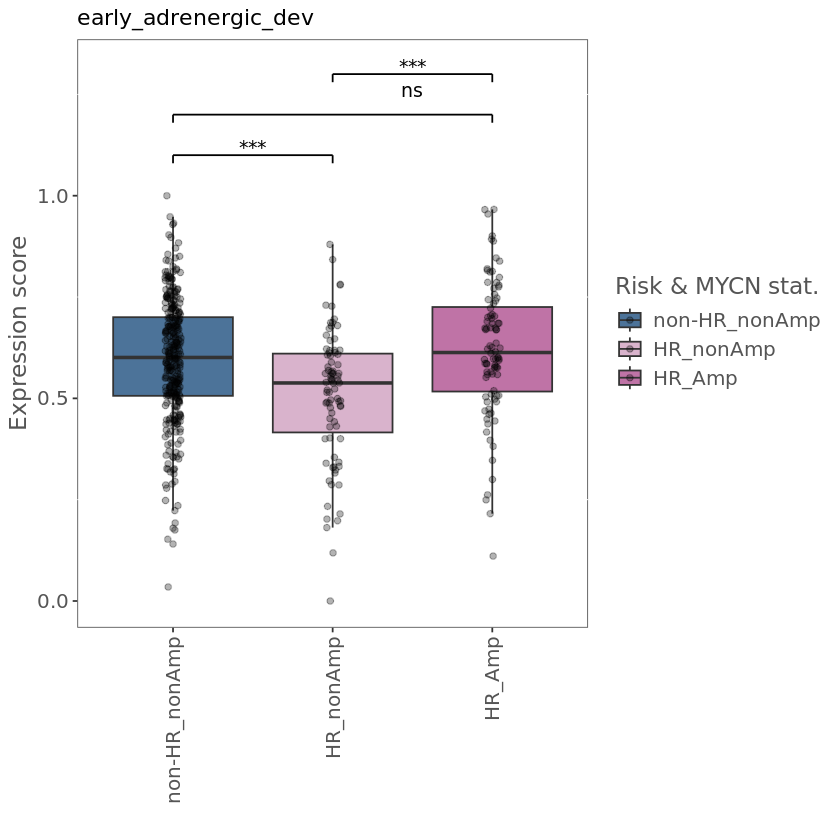

In [38]:
# Calculate scores and plot PDFs with stats

for(i in 1:length(modules_all)){

    module_name <- names(modules_all)[i]
    module <- modules_all[[i]]
    
    module <- module[module %in% rownames(filtered_matrix)]
    
    if(length(module) < 5){
        print(paste0('too few genes for signature ', module_name))
        next
    }
    
    genescores <- AddGeneSetScore(filtered_matrix, features = module)

    genescores_plot <- genescores

    genescores_plot$sample_id <- sapply(strsplit(rownames(genescores_plot), "_"), "[", 2)

    genescores_plot <- left_join(genescores_plot, meta_dat, by = 'sample_id')
    rownames(genescores_plot) <- genescores_plot$sample

    
    significant_pairs <- pairwise_wilcox_for_plot(set_name = 'Set1', group_name = 'HR_MYCN', dataframe = genescores_plot)
    significant_pairs$group1 <- factor(significant_pairs$group1, levels = levels(genescores_plot$HR_MYCN))
    significant_pairs$group2 <- factor(significant_pairs$group2, levels = levels(genescores_plot$HR_MYCN))
    
    significant_pairs <- significant_pairs %>%
      mutate(
        y_label_offset = case_when(
          label == "ns"  ~ 0.06,  # closer to the line
          label == "*"   ~ 0.02,
          label == "**"  ~ 0.02,
          label == "***" ~ 0.02,
          TRUE           ~ 0.03    # fallback
        ),
        y_label_position = y_position + y_label_offset
      )
    
    pdf(paste0("pics/Histogram_ModScore_Module_",module_name,"_by_MYCN_and_Risk_status_withStats.pdf"), width = 4.7, height = 3.9)
        print(
            ggplot(genescores_plot %>% filter(!is.na(HR_MYCN)),aes(x=HR_MYCN,y=Set1,fill=HR_MYCN)) +
                      geom_boxplot(outlier.shape=NA, alpha = 0.75) + 
                      geom_point(position=position_jitterdodge(jitter.width = 0.25),alpha = 0.3) +
                    # Horizontal lines for significance
                      geom_segment(data = significant_pairs, 
                                   aes(x = group1, xend = group2,
                                       y = y_position, yend = y_position), 
                                   inherit.aes = FALSE, color = "black") +
                      # Vertical lines at the ends of the horizontal line
                      geom_segment(data = significant_pairs,
                                   aes(x = group1, xend = group1,
                                       y = y_position, yend = y_position - 0.02),  # Adjust height as needed
                                   inherit.aes = FALSE, color = "black") +
                      geom_segment(data = significant_pairs,
                                   aes(x = group2, xend = group2,
                                       y = y_position, yend = y_position - 0.02),  # Adjust height as needed
                                   inherit.aes = FALSE, color = "black") +
                      geom_text(data = significant_pairs,
                                  aes(x = (as.numeric(factor(group1)) + 0.5), 
                                      y = y_label_position, 
                                      label = label),
                                  inherit.aes = FALSE,
                                  size = 4) +
                      scale_fill_manual(values = tol21rainbow[c(4,3,2)]) +
                      labs(fill = "Risk & MYCN stat.", title = paste0(module_name), y = 'Expression score', x = '') +
                      mytheme_angledX
            )
    dev.off()

    
    # print one plot inline
    if(i == 1){
        print(
            ggplot(genescores_plot %>% filter(!is.na(HR_MYCN)),aes(x=HR_MYCN,y=Set1,fill=HR_MYCN)) +
                          geom_boxplot(outlier.shape=NA, alpha = 0.75) + 
                          geom_point(position=position_jitterdodge(jitter.width = 0.25),alpha = 0.3) +
                        # Horizontal lines for significance
                          geom_segment(data = significant_pairs, 
                                       aes(x = group1, xend = group2,
                                           y = y_position, yend = y_position), 
                                       inherit.aes = FALSE, color = "black") +
                          # Vertical lines at the ends of the horizontal line
                          geom_segment(data = significant_pairs,
                                       aes(x = group1, xend = group1,
                                           y = y_position, yend = y_position - 0.02),  # Adjust height as needed
                                       inherit.aes = FALSE, color = "black") +
                          geom_segment(data = significant_pairs,
                                       aes(x = group2, xend = group2,
                                           y = y_position, yend = y_position - 0.02),  # Adjust height as needed
                                       inherit.aes = FALSE, color = "black") +
                          geom_text(data = significant_pairs,
                                      aes(x = (as.numeric(factor(group1)) + 0.5), 
                                          y = y_label_position, 
                                          label = label),
                                      inherit.aes = FALSE,
                                      size = 4) +
                          scale_fill_manual(values = tol21rainbow[c(4,3,2)]) +
                          labs(fill = "Risk & MYCN stat.", title = paste0(module_name), y = 'Expression score', x = '') +
                          mytheme_angledX
            )
    
    }
    
    # collect all data to write to file later
    significant_pairs$module <- module_name
    significant_pairs <- significant_pairs[,c('group1','group2','p_value','module')]

    if(i == 1){
        colnames(genescores_plot)[colnames(genescores_plot) == 'Set1'] <- module_name
        all_scores <- genescores_plot
        all_sig <- significant_pairs
        
    }else{
    
        genescores_plot <- genescores_plot[,c('Set1','sample_id')]
        colnames(genescores_plot)[colnames(genescores_plot) == 'Set1'] <- module_name
    
        all_scores <- left_join(all_scores, genescores_plot, by = 'sample_id')
        all_sig <- rbind(all_sig, significant_pairs)
    
    }
    
}

In [43]:
# write source data

write.csv(all_scores, '../../../source_data_figs/source_data_s6f_scores.csv', quote = F)
write.csv(all_sig, '../../../source_data_figs/source_data_s6f_sig.csv', quote = F)


# Processing and analysis of TARGET NBL cohort bulk RNA-seq data

In [48]:
# Set working directory and load relevant packages
library(plyr)
library(dplyr)
library(ggrepel)
library(ggplot2)
library(DescTools)
library(dplyr)
library(tidyr)
library(DESeq2)

source("../sc_analysis_palettes_and_helpers.r")

setwd('data/bulkRNAseq/TARGET/')

## Load data

### Get and filter mutational data
from Brady, S.W., Liu, Y., Ma, X. et al. Pan-neuroblastoma analysis reveals age- and signature-associated driver alterations. Nat Commun 11, 5183 (2020). https://doi.org/10.1038/s41467-020-18987-4


In [2]:
mutdat <- read.table("TARGET_NB_mutInfo.csv", sep = ";", stringsAsFactors = F, header = T) 


In [3]:
mutdat <- mutdat[mutdat$alias %like any% 'TARGET%',]
mutdat$alias <- gsub('-01A-01D','',mutdat$alias)
mutdat$alias <- gsub('-01A-01W','',mutdat$alias)
mutdat$alias <- gsub('-02A-01D','',mutdat$alias)


table(duplicated(mutdat$alias))

mutdat <- mutdat[!duplicated(mutdat$alias),]


FALSE  TRUE 
  317    10 

### Get expression data and clinical data

In [4]:
expr_red <- read.table("expr_counts_geneNames_all.csv", sep = ",", stringsAsFactors = F) 


In [5]:
## Read in metadata and create DEseq2-object
metadata <- read.delim("metadata_clin_all.csv", sep = "\t", stringsAsFactors = F, row.names = 1)
metadata_short <- read.delim("metadata_clin_all_short.csv", sep = ",", stringsAsFactors = F, row.names = 1)


In [6]:
metadata <- metadata[metadata$type == 'NB',]
metadata_short <- metadata_short[metadata_short$type == 'NB',]

### Add mutational info

In [7]:
metadata <- metadata[metadata$case_submitter_id %in% mutdat$alias,]
mutdat <- mutdat[mutdat$alias %in% metadata$case_submitter_id,]

In [8]:
mutdat <- mutdat[,colnames(mutdat)[!colnames(mutdat) %in% c('X...sample','COG.USI','DorR')]]

In [9]:
mutdat$case_submitter_id <- mutdat$alias

metadata <- left_join(metadata,mutdat, by = 'case_submitter_id')

In [10]:
metadata_short <- metadata_short[metadata_short$case_id %in% metadata$case_id,]

metadata$file_id <- gsub("-", ".", metadata_short$files.file_id)
metadata$file_id <- sub("^(\\d)", "X\\1", metadata$file_id)

rownames(metadata) <- metadata$file_id
metadata <- metadata[rownames(metadata) %in% colnames(expr_red),]

table(rownames(metadata) %in% colnames(expr_red))


TRUE 
 151 

## Filter data

In [11]:
# Remove PCPG samples and samples without metadata info from the matrix

expr_red <- expr_red[,colnames(expr_red) %in% rownames(metadata)]
metadata <- metadata[colnames(expr_red),]

table(rownames(metadata) == colnames(expr_red))


TRUE 
 151 

In [12]:
# Keep only genes that have a count above 10 in more than four samples

# Define the condition: value >= 10
condition <- expr_red >= 10

# Apply the condition to each row and count how many columns meet it
row_counts <- apply(condition, 1, sum)

# Filter rows where at least 4 columns meet the condition
filtered_matrix <- expr_red[row_counts > 4, ]

dim(filtered_matrix)

[1] 34514   151

In [14]:
# Remove everything after and including the comma in the primary diagnosis column
metadata$primary_diagnosis <- sub(",.*", "", metadata$primary_diagnosis)
metadata$primary_diagnosis <- sub(" ", "_", metadata$primary_diagnosis)

# Exchange NAs in the INSS risk group column
metadata$inss_stage <- sub("Stage ", "", metadata$inss_stage)
metadata$inss_stage[is.na(metadata$inss_stage)] <- metadata$type[is.na(metadata$inss_stage)]

metadata$group <- paste0(metadata$primary_diagnosis, '_', metadata$inss_stage)

metadata$stage_mycn <-paste0(metadata$inss_stage, '_', metadata$MYCN)

## Load into DEseq2 and process

In [15]:
ddsMat <- DESeqDataSetFromMatrix(countData = filtered_matrix,
                                 colData = metadata,
                                 design = ~ group
                                )

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [16]:
# Normalize with variance stabilizing transformation (VST) 

vsd <- vst(ddsMat, blind = FALSE)

## Score modules

### Load zebrafish NB modules and score those

In [40]:
modules_pan <- read.csv(file = '../../../final_mod_mat_DRNB_HSversion_finalNames.csv', stringsAsFactors = F, sep = ',', row.names = 1, header = T)

modules_pan <- as.list(modules_pan)
modules_pan <- lapply(modules_pan, function(x) x[!is.na(x)])
modules_pan <- lapply(modules_pan, function(x) x[x != 'NA'])
modules_pan <- lapply(modules_pan, function(x) x[x %in% rownames(filtered_matrix)])

modules_all <- modules_pan[lengths(modules_pan) > 5]
                      
# adjust to short names
names(modules_all)[names(modules_all) == 'nervous_system_dev_neuronprojection'] <- 'neuron_projection'
names(modules_all)[names(modules_all) == 'nervous_system_dev_01'] <- 'nervous_system_dev'
                      


In [41]:
# Define function for getting stats in a format allowing to add them to a plot downstream

pairwise_wilcox_for_plot <- function(set_name, group_name, dataframe){

    # Perform pairwise Wilcoxon tests
        pairwise_results <- pairwise.wilcox.test(
          dataframe[, set_name],  # Scores
          dataframe[, group_name],        # Grouping variable
          p.adjust.method = "bonferroni"  # Adjust method
        )

        # Convert pairwise results to a long format dataframe
        significant_pairs <- as.data.frame(pairwise_results$p.value) %>%
          tibble::rownames_to_column("group1") %>%
          pivot_longer(cols = -group1, names_to = "group2", values_to = "p_value") %>%
          filter(!is.na(p_value))  # Filter significant results
        #  filter(!is.na(p_value) & p_value < 0.05)  # Filter significant results

        # Define y positions for annotation lines
        y_positions <- seq(max(dataframe[, set_name]) + 0.1, 
                           by = 0.1, length.out = nrow(significant_pairs))

        significant_pairs <- significant_pairs %>%
          mutate(y_position = y_positions,
                 label = case_when(
                   p_value < 0.0001 ~ "***",
                   p_value < 0.001  ~ "**",
                   p_value < 0.01  ~ "*",
                   p_value >= 0.01 ~ "ns"
                 ))
        
        return(significant_pairs)

}

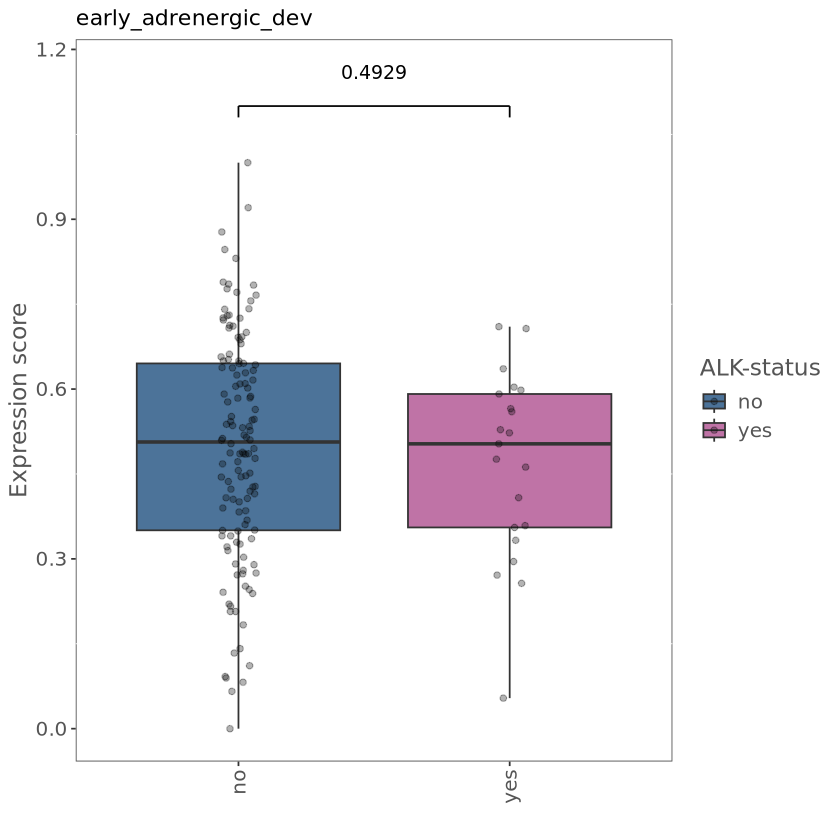

In [42]:
# PDF Boxplots across all NB diagnoses (NB and GanglioNB) with Stats FOR THESIS!!!!

for(i in 1:length(modules_all)){

    module_name <- names(modules_all)[i]
    module <- modules_all[[i]]
    
    module <- module[module %in% rownames(assay(vsd))]
    
    if(length(module) < 5){
        print(paste0('too few genes for signature ', module_name))
    }
    
    
    genescores <- AddGeneSetScore(vsd, features = module)

    genescores_plot <- as.data.frame(colData(genescores))

    genescores_plot$MYCN <- factor(genescores_plot$MYCN, levels = c('no','yes'))   
    genescores_plot$ATRX <- factor(genescores_plot$ATRX, levels = c('no','yes'))   
    genescores_plot$ALK <- factor(genescores_plot$ALK, levels = c('no','yes'))   
    genescores_plot$TERT <- factor(genescores_plot$TERT, levels = c('no','yes'))   
    
    genescores_plot$inss_stage[genescores_plot$inss_stage == '2B'] <- '2'
    genescores_plot$MYCN <- as.character(genescores_plot$MYCN)
    genescores_plot$MYCN[!is.na(genescores_plot$MYCN) & genescores_plot$MYCN == 'yes'] <- 'Amp'
    genescores_plot$MYCN[!is.na(genescores_plot$MYCN) & genescores_plot$MYCN == 'no'] <- 'nonAmp'
    genescores_plot$MYCN <- factor(genescores_plot$MYCN, levels = c('nonAmp','Amp'))   
    genescores_plot$stage_mycn <- paste0(genescores_plot$MYCN,'_',genescores_plot$inss_stage)
    genescores_plot$stage_mycn[genescores_plot$stage_mycn %like any% 'NA%'] <- NA

    genescores_plot$cog_neuroblastoma_risk_group <- factor(genescores_plot$cog_neuroblastoma_risk_group, levels = c('Low Risk','Intermediate Risk','High Risk'))


    significant_pairs <- pairwise_wilcox_for_plot(set_name = 'Set1', group_name = 'ALK', dataframe = genescores_plot)
    significant_pairs <- significant_pairs[significant_pairs$group1 != 'NA' & significant_pairs$group2 != 'NA',]

    
    significant_pairs <- significant_pairs %>%
      mutate(
        y_label_offset = case_when(
          label == "ns"  ~ 0.06,  # closer to the line
          label == "*"   ~ 0.02,
          label == "**"  ~ 0.02,
          label == "***" ~ 0.02,
          TRUE           ~ 0.03    # fallback
        ),
        y_label_position = y_position + y_label_offset
      )
    
    significant_pairs$p_value <- round(significant_pairs$p_value, 4)
    
    significant_pairs$plot_label <- as.character(significant_pairs$label)
    significant_pairs$plot_label[significant_pairs$label == 'ns'] <- significant_pairs$p_value[significant_pairs$label == 'ns']
    
    pdf(paste0("pics/Histogram_ModScore_NBOnly_Module_",module_name,"_perAlk_withStats.pdf"), width = 4, height = 2.6)
        print(
        ggplot(genescores_plot %>% filter(!is.na(ALK)),aes(x=ALK,y=Set1,fill=ALK)) +
                      geom_boxplot(outlier.shape=NA, alpha = 0.75) + 
                      geom_point(position=position_jitterdodge(jitter.width = 0.2),alpha = 0.3) +
                    # Horizontal lines for significance
                      geom_segment(data = significant_pairs, 
                                   aes(x = group1, xend = group2,
                                       y = y_position, yend = y_position), 
                                   inherit.aes = FALSE, color = "black") +
                      # Vertical lines at the ends of the horizontal line
                      geom_segment(data = significant_pairs,
                                   aes(x = group1, xend = group1,
                                       y = y_position, yend = y_position - 0.02),  # Adjust height as needed
                                   inherit.aes = FALSE, color = "black") +
                      geom_segment(data = significant_pairs,
                                   aes(x = group2, xend = group2,
                                       y = y_position, yend = y_position - 0.02),  # Adjust height as needed
                                   inherit.aes = FALSE, color = "black") +
                      geom_text(data = significant_pairs,
                                  aes(x = (as.numeric(factor(group1)) + 0.5), 
                                      y = y_label_position, 
                                      label = p_value),
                                  inherit.aes = FALSE,
                                  size = 4) +
                      scale_fill_manual(values = tol21rainbow[c(4,2)]) +
                      labs(fill = "ALK-status", title = paste0(module_name), y = 'Expression score', x = '' ) +
                      mytheme_angledX
        )
    dev.off()    
    
    # print one plot inline
    if(i == 1){
        print(
            ggplot(genescores_plot %>% filter(!is.na(ALK)),aes(x=ALK,y=Set1,fill=ALK)) +
                          geom_boxplot(outlier.shape=NA, alpha = 0.75) + 
                          geom_point(position=position_jitterdodge(jitter.width = 0.2),alpha = 0.3) +
                        # Horizontal lines for significance
                          geom_segment(data = significant_pairs, 
                                       aes(x = group1, xend = group2,
                                           y = y_position, yend = y_position), 
                                       inherit.aes = FALSE, color = "black") +
                          # Vertical lines at the ends of the horizontal line
                          geom_segment(data = significant_pairs,
                                       aes(x = group1, xend = group1,
                                           y = y_position, yend = y_position - 0.02),  # Adjust height as needed
                                       inherit.aes = FALSE, color = "black") +
                          geom_segment(data = significant_pairs,
                                       aes(x = group2, xend = group2,
                                           y = y_position, yend = y_position - 0.02),  # Adjust height as needed
                                       inherit.aes = FALSE, color = "black") +
                          geom_text(data = significant_pairs,
                                      aes(x = (as.numeric(factor(group1)) + 0.5), 
                                          y = y_label_position, 
                                          label = p_value),
                                      inherit.aes = FALSE,
                                      size = 4) +
                          scale_fill_manual(values = tol21rainbow[c(4,2)]) +
                          labs(fill = "ALK-status", title = paste0(module_name), y = 'Expression score', x = '' ) +
                          mytheme_angledX
        )
    
    }
    
    # collect all data to write to file later
    significant_pairs$module <- module_name
    significant_pairs <- significant_pairs[,c('group1','group2','p_value','module')]

    if(i == 1){
        colnames(genescores_plot)
        colnames(genescores_plot)[colnames(genescores_plot) == 'Set1'] <- module_name
        all_scores <- genescores_plot
        all_sig <- significant_pairs
        
    }else{
    
        genescores_plot <- genescores_plot[,c('Set1','file_id')]
        colnames(genescores_plot)[colnames(genescores_plot) == 'Set1'] <- module_name
    
        all_scores <- left_join(all_scores, genescores_plot, by = 'file_id')
        all_sig <- rbind(all_sig, significant_pairs)
    
    }  
    
}

In [46]:
# write source data
all_scores <- sapply(all_scores, function(x) gsub(',','_',x))
write.csv(all_scores, '../../../source_data_figs/source_data_s6g_scores.csv', quote = F)
write.csv(all_sig, '../../../source_data_figs/source_data_s6g_sig.csv', quote = F)
